# Vehicle Fuel Consumption Analysis and Visualization

**Course:** EDAV (22ADC32N) - Course-End Project | **Dept.:** Information Technology, CBIT | **Sem:** III (2026-27)

**Student:** VEMULA AKASH| **Roll No.:** 160125737914

**Objective:** Analyze a vehicle dataset to explore fuel-efficiency (miles per gallon) patterns using NumPy, Pandas and visualization tools, and develop insights into the factors - engine size, weight, power, country of origin and model year - that influence how much fuel a car uses.

**Workflow (as required):** Data Cleaning -> Analysis -> Visualization -> Conclusion

**How this project maps to the Titanic sample brief**

| Titanic sample | This project (Vehicle Fuel Consumption) |
|---|---|
| Survived / Not survived | **Efficient** (>= 25 mpg) / **Inefficient** (< 25 mpg) car |
| Age | MPG, weight, horsepower, displacement, acceleration |
| Pclass (passenger class) | Number of cylinders / weight class |
| Sex | Origin (usa / japan / europe) |
| Embarked port | Origin (usa / japan / europe) |
| Cabin = 'Unknown' | Car name = 'Unknown' |

**Notebook order:** Setup -> Dataset -> Data inspection -> **Q3 (cleaning, run first)** -> Q1 -> Q2 -> Q4 -> Q5 -> Final conclusion.

## 0. Environment Setup

```
pip install numpy pandas matplotlib seaborn
```

In [11]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
pd.set_option('display.max_columns', 30)
np.random.seed(42)   # reproducibility

ORIGIN_COLORS = {'usa': '#4C72B0', 'japan': '#DD8452', 'europe': '#55A868'}   # same colour for every chart

## 0.1 The Dataset

`vehicle_fuel_data.csv` holds one row per car: **398 vehicles of model years 1970-1982**, 9 columns.

| Column | Meaning |
|---|---|
| `mpg` | Fuel efficiency in miles per US gallon (higher = better) - the main variable of the project |
| `cylinders` | Number of engine cylinders (3, 4, 5, 6 or 8) |
| `displacement` | Engine size in cubic inches |
| `horsepower` | Engine power |
| `weight` | Vehicle weight in pounds |
| `acceleration` | Seconds taken to reach 60 mph (smaller = quicker) |
| `model_year` | Two-digit model year (70 = 1970) |
| `origin` | Where the brand comes from: `usa`, `japan` or `europe` |
| `name` | Brand and model of the car |

**About the data:** the columns, units and value ranges follow the classic *Auto-MPG* dataset used in data-science courses, so this notebook also works on that original file. The values in the CSV supplied with this project are **simulated** by the generator cell below (fixed random seed, so the file is identical every time). A few typical data-quality problems were added on purpose - duplicate rows, text (`?`) inside a numeric column, impossible values and missing values - so that the cleaning step (Q3) has genuine work to do.

If you want to use the original Auto-MPG data instead, save it next to this notebook as `vehicle_fuel_data.csv` with the same column names; every cell runs unchanged, but the numbers quoted in the conclusion cells must then be re-read from the new outputs.

**Dataset generator** - it runs only when `vehicle_fuel_data.csv` is missing, so anybody who opens this notebook gets exactly the same data.

In [9]:
import numpy as np, pandas as pd

def generate_vehicle_dataset(path='vehicle_fuel_data.csv', n=398, seed=42):
    """Create a realistic vehicle fuel-consumption dataset (same schema as the classic Auto-MPG data)."""
    rng = np.random.default_rng(seed)

    origin = rng.choice(['usa', 'japan', 'europe'], size=n, p=[0.62, 0.21, 0.17])
    year   = rng.integers(70, 83, size=n)                       # model years 1970-1982

    cyl = np.empty(n, dtype=int)
    for i, o in enumerate(origin):
        if o == 'usa':
            cyl[i] = rng.choice([4, 6, 8], p=[0.32, 0.28, 0.40])
        elif o == 'japan':
            cyl[i] = rng.choice([3, 4, 6], p=[0.04, 0.92, 0.04])
        else:
            cyl[i] = rng.choice([4, 5, 6], p=[0.85, 0.07, 0.08])

    disp_ranges = {3: (70, 80), 4: (85, 150), 5: (121, 183), 6: (145, 262), 8: (260, 455)}
    displacement = np.array([rng.uniform(*disp_ranges[c]) for c in cyl]).round(0)

    horsepower = 38 + 0.30 * displacement - 0.8 * (year - 70) + rng.normal(0, 11, n)
    horsepower = np.clip(horsepower, 46, 230).round(0)

    weight = 1750 + 6.2 * displacement + 0.12 * horsepower * 3 + rng.normal(0, 230, n)
    weight = np.clip(weight, 1600, 5200).round(0)

    acceleration = 15.6 - 0.045 * (horsepower - 104) + rng.normal(0, 1.5, n)
    acceleration = np.clip(acceleration, 8.0, 24.8).round(1)

    mpg = (37.0 - 0.0062 * weight + 0.62 * (year - 70)
           + np.where(origin == 'japan', 2.0, np.where(origin == 'europe', 1.2, 0.0))
           + rng.normal(0, 2.6, n))
    mpg = np.clip(mpg, 9.0, 46.6).round(1)

    models = {
        'usa':    [('chevrolet', ['chevelle malibu', 'impala', 'nova', 'vega 2300', 'monte carlo']),
                   ('ford', ['torino', 'mustang ii', 'pinto', 'maverick', 'granada']),
                   ('plymouth', ['fury iii', 'duster', 'volare', 'satellite']),
                   ('dodge', ['colt', 'aspen', 'dart custom', 'monaco']),
                   ('buick', ['skylark', 'century', 'regal sport coupe']),
                   ('amc', ['rebel sst', 'hornet', 'gremlin', 'pacer']),
                   ('pontiac', ['catalina', 'firebird', 'ventura']),
                   ('oldsmobile', ['cutlass supreme', 'omega'])],
        'japan':  [('toyota', ['corolla', 'corona', 'celica gt', 'tercel']),
                   ('datsun', ['510', 'b210', '210', '710']),
                   ('honda', ['civic', 'accord', 'civic cvcc']),
                   ('mazda', ['glc', 'rx-4', '626']),
                   ('subaru', ['dl', 'brat'])],
        'europe': [('volkswagen', ['rabbit', 'dasher', 'beetle', 'scirocco']),
                   ('fiat', ['128', 'strada custom', 'x1-9']),
                   ('peugeot', ['504', '505s turbo diesel']),
                   ('volvo', ['245', '144ea']),
                   ('bmw', ['2002']), ('audi', ['100 ls', 'fox']),
                   ('saab', ['99e', '900s']), ('renault', ['12tl', '5 gtl'])],
    }
    names = []
    for o in origin:
        brand, mods = models[o][rng.integers(len(models[o]))]
        names.append(f'{brand} {mods[rng.integers(len(mods))]}')

    df = pd.DataFrame({'mpg': mpg, 'cylinders': cyl, 'displacement': displacement,
                       'horsepower': horsepower, 'weight': weight, 'acceleration': acceleration,
                       'model_year': year, 'origin': origin, 'name': names})

    # ---- realistic data-quality problems (so that the cleaning step has real work to do) ----
    df['horsepower'] = df['horsepower'].astype('object')
    df.loc[rng.choice(n, 6, replace=False), 'horsepower'] = '?'        # text placeholder, as in the classic dataset
    df.loc[rng.choice(n, 9, replace=False), 'horsepower'] = np.nan
    df.loc[rng.choice(n, 2, replace=False), 'horsepower'] = 0          # impossible value
    df.loc[rng.choice(n, 5, replace=False), 'acceleration'] = np.nan
    df.loc[rng.choice(n, 4, replace=False), 'weight'] = np.nan
    df.loc[rng.choice(n, 1, replace=False), 'weight'] = 350            # typo (should be ~3500)
    df.loc[rng.choice(n, 8, replace=False), 'name'] = np.nan
    df = pd.concat([df, df.sample(6, random_state=7)], ignore_index=True)   # 6 duplicated rows
    df = df.sample(frac=1, random_state=11).reset_index(drop=True)
    df.to_csv(path, index=False)
    return df


# ---- runs only if the CSV is missing; the seed makes the generated data identical every time ----
CSV_PATH = 'vehicle_fuel_data.csv'
if not os.path.exists(CSV_PATH):
    generate_vehicle_dataset(CSV_PATH)
    print('Dataset generated and saved ->', CSV_PATH)
else:
    print(CSV_PATH, 'already exists - using it.')

vehicle_fuel_data.csv already exists - using it.


## 1. Dataset Inspection

**Concept:** Before any analysis we inspect shape, data types, missing values, duplicates and basic statistics to find problems that must be fixed.

In [ ]:
raw = pd.read_csv(CSV_PATH)
print('Shape (rows, columns):', raw.shape)
print('Origins:', raw['origin'].unique().tolist())
print()
raw.info()
display(raw.head())

Shape (rows, columns): (404, 9)
Origins: ['japan', 'europe', 'usa']

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 404 entries, 0 to 403
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           404 non-null    float64
 1   cylinders     404 non-null    int64  
 2   displacement  404 non-null    float64
 3   horsepower    395 non-null    object 
 4   weight        400 non-null    float64
 5   acceleration  399 non-null    float64
 6   model_year    404 non-null    int64  
 7   origin        404 non-null    object 
 8   name          396 non-null    object 
dtypes: float64(4), int64(2), object(3)
memory usage: 28.5+ KB


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,27.20,4,129.00,88.0,"2,127.00",15.70,73,japan,subaru dl
1,32.70,4,139.00,67.0,"2,570.00",17.50,81,japan,toyota tercel
2,29.80,4,95.00,58.0,NaN,21.00,77,europe,bmw 2002
3,28.70,4,96.00,70.0,"2,186.00",18.40,77,japan,toyota celica gt
4,19.70,8,344.00,134.0,"3,850.00",14.50,77,usa,ford maverick


In [ ]:
print('Missing values per column:')
display(raw.isnull().sum())
print('Fully duplicated rows:', raw.duplicated().sum())

# horsepower is stored as text - find the non-numeric entries that caused it
hp_text = raw['horsepower'][pd.to_numeric(raw['horsepower'], errors='coerce').isna() & raw['horsepower'].notna()]
print("Non-numeric entries in 'horsepower':", hp_text.unique().tolist(), '->', len(hp_text), 'rows')
display(raw.describe(include='all').T)

Missing values per column:


,0
mpg,0
cylinders,0
displacement,0
horsepower,9
weight,4
acceleration,5
model_year,0
origin,0
name,8


Fully duplicated rows: 6
Non-numeric entries in 'horsepower': ['?'] -> 4 rows


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
mpg,404.00,NaN,NaN,NaN,23.17,5.91,9.00,19.60,23.65,27.40,38.00
cylinders,404.00,NaN,NaN,NaN,5.34,1.67,3.00,4.00,4.00,6.00,8.00
displacement,404.00,NaN,NaN,NaN,191.26,104.55,73.00,113.00,143.00,249.75,455.00
horsepower,395,115,46.0,13,NaN,NaN,NaN,NaN,NaN,NaN,NaN
weight,400.00,NaN,NaN,NaN,"2,942.54",703.30,350.00,"2,437.00","2,742.00","3,303.00","4,921.00"
acceleration,399.00,NaN,NaN,NaN,16.25,2.28,9.30,14.80,16.50,17.85,22.10
model_year,404.00,NaN,NaN,NaN,75.93,3.72,70.00,73.00,76.00,79.00,82.00
origin,404,3,usa,249,NaN,NaN,NaN,NaN,NaN,NaN,NaN
name,396,63,buick regal sport coupe,13,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
import os
import numpy as np
import pandas as pd

# Set options to show all rows and columns
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

def generate_vehicle_dataset(path='vehicle_fuel_data.csv', n=398, seed=42):
    rng = np.random.default_rng(seed)
    origin = rng.choice(['usa', 'japan', 'europe'], size=n, p=[0.62, 0.21, 0.17])
    year   = rng.integers(70, 83, size=n)
    cyl = np.empty(n, dtype=int)
    for i, o in enumerate(origin):
        if o == 'usa':
            cyl[i] = rng.choice([4, 6, 8], p=[0.32, 0.28, 0.40])
        elif o == 'japan':
            cyl[i] = rng.choice([3, 4, 6], p=[0.04, 0.92, 0.04])
        else:
            cyl[i] = rng.choice([4, 5, 6], p=[0.85, 0.07, 0.08])
    disp_ranges = {3: (70, 80), 4: (85, 150), 5: (121, 183), 6: (145, 262), 8: (260, 455)}
    displacement = np.array([rng.uniform(*disp_ranges[c]) for c in cyl]).round(0)
    horsepower = 38 + 0.30 * displacement - 0.8 * (year - 70) + rng.normal(0, 11, n)
    horsepower = np.clip(horsepower, 46, 230).round(0)
    weight = 1750 + 6.2 * displacement + 0.12 * horsepower * 3 + rng.normal(0, 230, n)
    weight = np.clip(weight, 1600, 5200).round(0)
    acceleration = 15.6 - 0.045 * (horsepower - 104) + rng.normal(0, 1.5, n)
    acceleration = np.clip(acceleration, 8.0, 24.8).round(1)
    mpg = (37.0 - 0.0062 * weight + 0.62 * (year - 70) + np.where(origin == 'japan', 2.0, np.where(origin == 'europe', 1.2, 0.0)) + rng.normal(0, 2.6, n))
    mpg = np.clip(mpg, 9.0, 46.6).round(1)
    models = {'usa': [('chevrolet', ['chevelle malibu', 'impala', 'nova', 'vega 2300', 'monte carlo']), ('ford', ['torino', 'mustang ii', 'pinto', 'maverick', 'granada']), ('plymouth', ['fury iii', 'duster', 'volare', 'satellite']), ('dodge', ['colt', 'aspen', 'dart custom', 'monaco']), ('buick', ['skylark', 'century', 'regal sport coupe']), ('amc', ['rebel sst', 'hornet', 'gremlin', 'pacer']), ('pontiac', ['catalina', 'firebird', 'ventura']), ('oldsmobile', ['cutlass supreme', 'omega'])], 'japan': [('toyota', ['corolla', 'corona', 'celica gt', 'tercel']), ('datsun', ['510', 'b210', '210', '710']), ('honda', ['civic', 'accord', 'civic cvcc']), ('mazda', ['glc', 'rx-4', '626']), ('subaru', ['dl', 'brat'])], 'europe': [('volkswagen', ['rabbit', 'dasher', 'beetle', 'scirocco']), ('fiat', ['128', 'strada custom', 'x1-9']), ('peugeot', ['504', '505s turbo diesel']), ('volvo', ['245', '144ea']), ('bmw', ['2002']), ('audi', ['100 ls', 'fox']), ('saab', ['99e', '900s']), ('renault', ['12tl', '5 gtl'])]}
    names = []
    for o in origin:
        brand, mods = models[o][rng.integers(len(models[o]))]
        names.append(f'{brand} {mods[rng.integers(len(mods))]}')
    df = pd.DataFrame({'mpg': mpg, 'cylinders': cyl, 'displacement': displacement, 'horsepower': horsepower, 'weight': weight, 'acceleration': acceleration, 'model_year': year, 'origin': origin, 'name': names})
    df['horsepower'] = df['horsepower'].astype('object')
    df.loc[rng.choice(n, 6, replace=False), 'horsepower'] = '?'
    df.loc[rng.choice(n, 9, replace=False), 'horsepower'] = np.nan
    df.loc[rng.choice(n, 2, replace=False), 'horsepower'] = 0
    df.loc[rng.choice(n, 5, replace=False), 'acceleration'] = np.nan
    df.loc[rng.choice(n, 4, replace=False), 'weight'] = np.nan
    df.loc[rng.choice(n, 1, replace=False), 'weight'] = 350
    df.loc[rng.choice(n, 8, replace=False), 'name'] = np.nan
    df = pd.concat([df, df.sample(6, random_state=7)], ignore_index=True)
    df = df.sample(frac=1, random_state=11).reset_index(drop=True)
    df.to_csv(path, index=False)
    return df

# Ensure dataset is generated if missing
CSV_PATH = 'vehicle_fuel_data.csv'
if not os.path.exists(CSV_PATH):
    generate_vehicle_dataset(CSV_PATH)

# Load and display the full dataframe
df = pd.read_csv(CSV_PATH)
df

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,27.2,4,129.0,88.0,2127.0,15.7,73,japan,subaru dl
1,32.7,4,139.0,67.0,2570.0,17.5,81,japan,toyota tercel
2,29.8,4,95.0,58.0,NaN,21.0,77,europe,bmw 2002
3,28.7,4,96.0,70.0,2186.0,18.4,77,japan,toyota celica gt
4,19.7,8,344.0,134.0,3850.0,14.5,77,usa,ford maverick
5,25.3,6,201.0,78.0,2608.0,16.6,80,usa,oldsmobile cutlass supreme
6,26.5,4,87.0,57.0,2168.0,18.5,75,usa,ford granada
7,25.3,4,97.0,49.0,2386.0,17.2,70,japan,toyota corona
8,18.9,6,192.0,102.0,3132.0,14.5,75,usa,plymouth satellite
9,11.7,8,370.0,151.0,4307.0,11.7,79,usa,amc hornet


**Observation:** The raw file has **404 rows and 9 columns**. Problems found: **6 completely duplicated rows**; `horsepower` is stored as *text* (it shows up as `str`/`object` instead of a number) because **4 entries contain `?`**; missing values in `horsepower` (9), `weight` (4), `acceleration` (5) and `name` (8); `mpg` is complete. The summary table also shows a `weight` minimum of **350 lb**, which is impossible for a car - most likely a typing error for 3,500 lb - and `horsepower` will contain impossible zeros once it is converted to numbers (checked in Q3).

## Q3. Handling Missing Values and Anomalies (Imputation)  `[CO3, BL3]`

**Concept:** The task is to prepare a clean dataset. In the Titanic data `Age` was filled with the median; here a single overall median would be wrong - an 8-cylinder car does not have the same horsepower or weight as a 3-cylinder car. So numeric gaps are filled with the **median of cars that have the same number of cylinders**. The text column `name` gets the placeholder `'Unknown'` (like Cabin in the Titanic brief). We also fix data types, remove duplicates, treat impossible values as missing, and create new columns used in the later questions. The target column `mpg` is never imputed.

In [ ]:
df = raw.copy()
num_cols = ['mpg', 'cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'model_year']

# 1) Fix data types: text such as '?' becomes NaN so that it can be imputed
df['horsepower'] = pd.to_numeric(df['horsepower'], errors='coerce')
for c in num_cols:
    df[c] = pd.to_numeric(df[c], errors='coerce')
print("dtype of 'horsepower' after conversion:", df['horsepower'].dtype)

# 2) Remove exact duplicate rows
n_dup = df.duplicated().sum()
df = df.drop_duplicates().reset_index(drop=True)
print('Duplicate rows removed:', n_dup)

# 3) Anomalies -> treat as missing (impossible physical values)
bad_hp     = df['horsepower'] <= 0          # an engine cannot have 0 hp
bad_weight = df['weight'] < 800             # no car in this data weighs under 800 lb (typing error)
print('Impossible horsepower values :', bad_hp.sum())
print('Impossible weight values     :', bad_weight.sum())
df.loc[bad_hp, 'horsepower'] = np.nan
df.loc[bad_weight, 'weight'] = np.nan

# 4) The target column (mpg) must never be guessed - drop a row only if mpg itself is missing
print('Rows without mpg dropped     :', df['mpg'].isna().sum())
df = df.dropna(subset=['mpg']).reset_index(drop=True)

print('\nMissing values BEFORE imputation:')
display(df.isnull().sum())

dtype of 'horsepower' after conversion: float64
Duplicate rows removed: 6
Impossible horsepower values : 2
Impossible weight values     : 1
Rows without mpg dropped     : 0

Missing values BEFORE imputation:


,0
mpg,0
cylinders,0
displacement,0
horsepower,15
weight,5
acceleration,5
model_year,0
origin,0
name,8


In [ ]:
# 5) Imputation
# Numeric columns -> median of cars with the SAME number of cylinders (engine size strongly decides hp, weight, etc.)
for col in ['horsepower', 'weight', 'acceleration', 'displacement']:
    group_median = df.groupby('cylinders')[col].transform('median')
    df[col] = df[col].fillna(group_median).fillna(df[col].median())   # overall median as a safety net

# Text column -> placeholder 'Unknown' (same idea as Cabin = 'Unknown' in the Titanic brief)
df['name'] = df['name'].fillna('Unknown')

# 6) Verify - no missing values may remain
assert df.isnull().sum().sum() == 0
print('Missing values AFTER imputation:', int(df.isnull().sum().sum()))
print('Rows in clean dataset:', len(df))

Missing values AFTER imputation: 0
Rows in clean dataset: 398


In [ ]:
# 7) Feature engineering (new columns used in Q1-Q5)
df['efficiency_class'] = np.where(df['mpg'] >= 25, 'Efficient', 'Inefficient')   # analogue of Survived / Not survived
df['is_efficient']     = (df['efficiency_class'] == 'Efficient').astype(int)
df['kmpl']             = df['mpg'] * 0.425144                                   # 1 US mpg = 0.4251 km per litre
df['year']             = 1900 + df['model_year']
df['brand']            = df['name'].str.split().str[0]                          # first word of the car name
df['weight_class']     = pd.qcut(df['weight'], 3, labels=['Light', 'Medium', 'Heavy'])
df['power_to_weight']  = df['horsepower'] / df['weight'] * 1000                 # hp per 1000 lb

print('Efficiency threshold: 25 mpg  (= %.1f km/L)' % (25 * 0.425144))
display(df.head())

Efficiency threshold: 25 mpg  (= 10.6 km/L)


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name,efficiency_class,is_efficient,kmpl,year,brand,weight_class,power_to_weight
0,27.20,4,129.00,88.00,"2,127.00",15.70,73,japan,subaru dl,Efficient,1,11.56,1973,subaru,Light,41.37
1,32.70,4,139.00,67.00,"2,570.00",17.50,81,japan,toyota tercel,Efficient,1,13.90,1981,toyota,Medium,26.07
2,29.80,4,95.00,58.00,"2,482.00",21.00,77,europe,bmw 2002,Efficient,1,12.67,1977,bmw,Light,23.37
3,28.70,4,96.00,70.00,"2,186.00",18.40,77,japan,toyota celica gt,Efficient,1,12.20,1977,toyota,Light,32.02
4,19.70,8,344.00,134.00,"3,850.00",14.50,77,usa,ford maverick,Inefficient,0,8.38,1977,ford,Heavy,34.81


,Lower fence,Upper fence,Outliers
Column,,,
mpg,7.96,39.06,0
horsepower,0.50,172.50,9
weight,"1,130.88","4,621.88",11
acceleration,10.25,22.45,6
displacement,-94.38,458.62,0


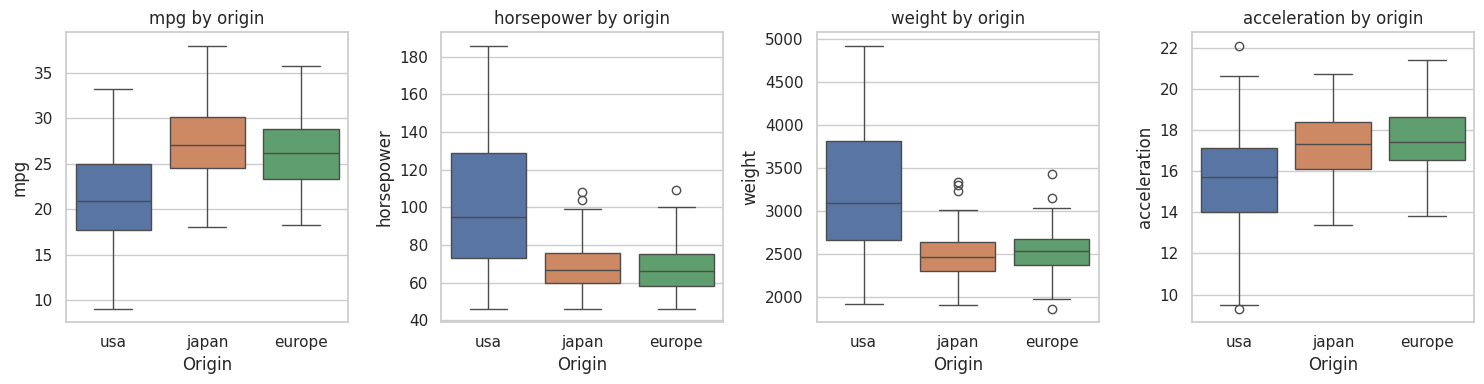

In [ ]:
# 8) Outlier check using the IQR rule (flagged, NOT removed - these are genuine vehicles)
rows = []
for col in ['mpg', 'horsepower', 'weight', 'acceleration', 'displacement']:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = int(((df[col] < low) | (df[col] > high)).sum())
    rows.append({'Column': col, 'Lower fence': low, 'Upper fence': high, 'Outliers': n_out})
display(pd.DataFrame(rows).set_index('Column'))

fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for ax, col in zip(axes, ['mpg', 'horsepower', 'weight', 'acceleration']):
    sns.boxplot(data=df, x='origin', y=col, order=['usa', 'japan', 'europe'], hue='origin',
                palette=ORIGIN_COLORS, dodge=False, ax=ax)
    if ax.get_legend() is not None:
        ax.get_legend().remove()
    ax.set_title(f'{col} by origin')
    ax.set_xlabel('Origin'); ax.set_ylabel(col)
plt.tight_layout()
plt.show()

**Conclusion / Insight (Q3):** 6 duplicate rows were removed and the 4 `?` entries were converted to missing values. Together with 2 impossible horsepower values (0 hp) and 1 impossible weight (350 lb) this left **15 missing horsepower, 5 weight, 5 acceleration and 8 car names** to repair. They were filled using the cylinder-group median (numbers) and `'Unknown'` (names); the `assert` confirms **0 missing values remain** and the clean dataset has **398 cars**. A global median (about 80 hp) would have given an 8-cylinder car the power of a small hatchback, which is why the group median was chosen.

The IQR check flagged 9 horsepower, 11 weight and 6 acceleration outliers (none for `mpg`). All of them are **8-cylinder cars** - very heavy, very powerful and slow to accelerate - so they are real vehicles, not errors, and were **kept**. The box plots, which are drawn per origin, also mark a few points that are unusual *for their own origin* (the heaviest and most powerful Japanese and European cars); these are genuine too. With the 25 mpg rule the clean data has **163 efficient and 235 inefficient cars (41% efficient)**, a balanced split for comparison.

## Q1. NumPy Statistics - Average, Minimum and Maximum by Group  `[CO1, BL3]`

**Concept:** Using only NumPy array operations (boolean masks with `np.mean`, `np.min`, `np.max`), we compute statistics for **Efficient vs Inefficient** cars - the equivalent of Survived vs Not survived - then for each cylinder count, and finally measure how strongly MPG is related to the other variables (`np.corrcoef`, `np.polyfit`).

In [ ]:
y   = df['mpg'].to_numpy()
cls = df['efficiency_class'].to_numpy()

features = {'MPG': 'mpg', 'km/L': 'kmpl', 'Weight (lb)': 'weight',
            'Horsepower': 'horsepower', 'Displacement (cu in)': 'displacement', 'Acceleration (s)': 'acceleration'}

# (a) Mean / Min / Max of each variable for Efficient vs Inefficient cars  (NumPy boolean masks)
rows = []
for label, col in features.items():
    arr = df[col].to_numpy()
    for grp in ['Efficient', 'Inefficient']:
        m = cls == grp
        rows.append({'Variable': label, 'Class': grp, 'Cars': int(m.sum()),
                     'Mean': np.mean(arr[m]), 'Min': np.min(arr[m]), 'Max': np.max(arr[m])})
q1a = pd.DataFrame(rows).set_index(['Variable', 'Class'])
print('(a) Average, minimum and maximum by efficiency class')
display(q1a)

(a) Average, minimum and maximum by efficiency class


Cars     Mean      Min      Max
Variable             Class                                       
MPG                  Efficient     163    28.64    25.00    38.00
                     Inefficient   235    19.37     9.00    24.90
km/L                 Efficient     163    12.18    10.63    16.16
                     Inefficient   235     8.24     3.83    10.59
Weight (lb)          Efficient     163 2,466.42 1,858.00 3,664.00
                     Inefficient   235 3,288.45 1,975.00 4,921.00
Horsepower           Efficient     163    68.26    46.00   120.00
                     Inefficient   235   104.60    46.00   186.00
Displacement (cu in) Efficient     163   122.21    73.00   316.00
                     Inefficient   235   239.11    74.00   455.00
Acceleration (s)     Efficient     163    17.28    11.60    22.10
                     Inefficient   235    15.55     9.30    20.60

In [ ]:
# (b) Mean / Min / Max / Std of MPG for every cylinder count
cyl = df['cylinders'].to_numpy()
rows = []
for c in np.unique(cyl):
    m = cyl == c
    rows.append({'Cylinders': int(c), 'Cars': int(m.sum()), 'Avg MPG': np.mean(y[m]),
                 'Min MPG': np.min(y[m]), 'Max MPG': np.max(y[m]), 'Std MPG': np.std(y[m])})
print('(b) MPG statistics by number of cylinders')
display(pd.DataFrame(rows).set_index('Cylinders'))

# (c) How strongly is MPG related to the other variables?  (np.corrcoef and np.polyfit)
print('\n(c) Correlation of MPG with other variables')
for label, col in [('Weight', 'weight'), ('Displacement', 'displacement'), ('Horsepower', 'horsepower'),
                   ('Acceleration', 'acceleration'), ('Model year', 'model_year')]:
    r = np.corrcoef(df[col].to_numpy(), y)[0, 1]
    print(f'   MPG vs {label:<13}: r = {r:6.3f}')

slope_w, _ = np.polyfit(df['weight'].to_numpy(), y, 1)
slope_y, _ = np.polyfit(df['model_year'].to_numpy(), y, 1)
print(f'\nTrend line: MPG changes by {slope_w * 1000:.2f} for every extra 1000 lb of weight')
print(f'Trend line: MPG changes by {slope_y:+.2f} per model year')

(b) MPG statistics by number of cylinders


,Cars,Avg MPG,Min MPG,Max MPG,Std MPG
Cylinders,,,,,
3,5,31.04,22.10,37.50,5.39
4,215,26.50,18.40,38.00,3.86
5,6,22.25,19.30,25.30,1.91
6,78,22.01,15.70,31.70,3.66
8,94,16.16,9.00,28.70,4.62



(c) Correlation of MPG with other variables
   MPG vs Weight       : r = -0.797
   MPG vs Displacement : r = -0.757
   MPG vs Horsepower   : r = -0.749
   MPG vs Acceleration : r =  0.582
   MPG vs Model year   : r =  0.416

Trend line: MPG changes by -6.76 for every extra 1000 lb of weight
Trend line: MPG changes by +0.66 per model year


**Conclusion / Insight (Q1):** Efficient cars average **28.6 mpg (12.2 km/L)** against **19.4 mpg (8.2 km/L)** for inefficient cars. The efficient group is clearly *lighter* (2,466 lb vs 3,288 lb), has *less power* (68 hp vs 105 hp) and a *smaller engine* (122 vs 239 cu in) - but it accelerates *slower* (17.3 s vs 15.6 s), so fuel economy is bought at the cost of performance. The ranges overlap (the lightest inefficient car weighs 1,975 lb, less than the heaviest efficient one at 3,664 lb), so weight alone does not decide efficiency.

By cylinders, the average MPG falls steadily: 4-cylinder **26.5**, 6-cylinder **22.0**, 8-cylinder **16.2** (3-cylinder 31.0 and 5-cylinder 22.3 are based on only 5 and 6 cars). **Weight** has the strongest relationship with MPG (r = -0.80), followed by displacement (-0.76) and horsepower (-0.75); every extra 1,000 lb costs about **6.8 mpg**. Newer cars are better: MPG rises by about **0.66 per model year** (r = +0.42).

## Q2. Pandas `groupby` - How Engine Size, Origin and Weight Influence Efficiency  `[CO2, BL4]`

**Concept:** Like analysing survival by passenger class and gender, we use `groupby` with aggregation to compute the **percentage of efficient cars** (the "survival rate") for each number of cylinders, each origin and each weight class, and then for two factors together (cylinders x origin) to see which factor really matters. We finish with model-year progress and a brand ranking.

In [ ]:
def summarize(g):
    return g.agg(Cars=('mpg', 'count'),
                 Avg_MPG=('mpg', 'mean'),
                 Avg_Weight=('weight', 'mean'),
                 Efficient_Pct=('is_efficient', lambda s: s.mean() * 100))

by_cyl    = summarize(df.groupby('cylinders'))
by_origin = summarize(df.groupby('origin'))
by_wclass = summarize(df.groupby('weight_class', observed=True))

print('Efficiency by number of cylinders');  display(by_cyl)
print('\nEfficiency by origin');              display(by_origin)
print('\nEfficiency by weight class');        display(by_wclass)

Efficiency by number of cylinders


,Cars,Avg_MPG,Avg_Weight,Efficient_Pct
cylinders,,,,
3,5,31.04,"2,161.40",80.00
4,215,26.50,"2,489.36",65.58
5,6,22.25,"2,806.33",16.67
6,78,22.01,"3,023.92",19.23
8,94,16.16,"4,000.94",2.13



Efficiency by origin


,Cars,Avg_MPG,Avg_Weight,Efficient_Pct
origin,,,,
europe,59,26.32,"2,540.47",61.02
japan,93,27.19,"2,489.16",68.82
usa,246,20.89,"3,225.33",25.61



Efficiency by weight class


,Cars,Avg_MPG,Avg_Weight,Efficient_Pct
weight_class,,,,
Light,133,27.63,"2,308.18",74.44
Medium,132,24.48,"2,758.12",46.21
Heavy,133,17.41,"3,787.60",2.26


In [ ]:
# Two factors together (like Pclass x Sex in the Titanic project): cylinders x origin
pt_eff = pd.pivot_table(df, index='cylinders', columns='origin', values='is_efficient', aggfunc='mean') * 100
pt_cnt = pd.pivot_table(df, index='cylinders', columns='origin', values='is_efficient', aggfunc='count').fillna(0).astype(int)
print('Efficient cars (%) - cylinders x origin  (blank = no such cars)');  display(pt_eff)
print('\nNumber of cars - cylinders x origin');                           display(pt_cnt)

# Weight class x origin: average MPG
pt_w = pd.pivot_table(df, index='weight_class', columns='origin', values='mpg', aggfunc='mean', observed=True)
print('\nAverage MPG - weight class x origin'); display(pt_w)

Efficient cars (%) - cylinders x origin  (blank = no such cars)


origin,europe,japan,usa
cylinders,,,
3,NaN,80.00,NaN
4,68.00,69.05,60.49
5,16.67,NaN,NaN
6,33.33,50.00,16.90
8,NaN,NaN,2.13



Number of cars - cylinders x origin


origin,europe,japan,usa
cylinders,,,
3,0,5,0
4,50,84,81
5,6,0,0
6,3,4,71
8,0,0,94



Average MPG - weight class x origin


origin,europe,japan,usa
weight_class,,,
Light,27.63,28.49,26.61
Medium,25.27,25.59,23.65
Heavy,20.85,21.17,17.27


In [ ]:
# Year-wise improvement and brand ranking
by_year = summarize(df.groupby('year'))
print('Year-wise performance'); display(by_year)

brand_tbl = (df[df['brand'] != 'Unknown'].groupby('brand')
             .agg(Cars=('mpg', 'count'), Avg_MPG=('mpg', 'mean'), Avg_Weight=('weight', 'mean')))
brand_tbl = brand_tbl[brand_tbl['Cars'] >= 5].sort_values('Avg_MPG', ascending=False)
print('\nBrands with at least 5 cars, ranked by average MPG')
display(brand_tbl)

Year-wise performance


,Cars,Avg_MPG,Avg_Weight,Efficient_Pct
year,,,,
1970,35,19.21,"3,041.46",25.71
1971,33,20.92,"2,783.45",12.12
1972,23,19.34,"3,156.35",8.70
1973,31,21.27,"2,982.77",29.03
1974,25,22.92,"2,848.00",44.00
1975,36,20.77,"3,123.75",27.78
1976,33,23.62,"2,908.97",45.45
1977,33,25.78,"2,716.24",54.55
1978,31,24.23,"2,953.81",48.39



Brands with at least 5 cars, ranked by average MPG


,Cars,Avg_MPG,Avg_Weight
brand,,,
subaru,17,28.42,"2,532.53"
honda,18,27.91,"2,436.89"
saab,6,27.50,"2,469.17"
renault,7,27.07,"2,651.14"
datsun,26,27.01,"2,521.73"
peugeot,6,26.88,"2,540.67"
volkswagen,9,26.70,"2,509.33"
toyota,18,26.33,"2,487.33"
mazda,13,26.23,"2,445.62"


**Conclusion / Insight (Q2):** Efficiency drops sharply with engine size: **80%** of 3-cylinder, **66%** of 4-cylinder, **19%** of 6-cylinder and only **2%** of 8-cylinder cars reach 25 mpg (5-cylinder: 17%, from just 6 cars). By origin, **Japan (69%)** and **Europe (61%)** lead, while the **USA has only 26%**. Weight class tells the same story: **74%** of light, **46%** of medium and **2%** of heavy cars are efficient.

The cylinders x origin table shows that most of the origin gap is a *car-mix effect*, not a "nationality" effect: among **4-cylinder cars** the shares are close (Europe 68%, Japan 69%, USA 60%), whereas the USA is the only origin with 8-cylinder cars (94 of them, 2% efficient). A smaller advantage remains even within the same weight class - Japanese and European cars are 1-3.5 mpg better than American ones (for heavy cars 21.2 / 20.9 vs 17.3 mpg).

Over time, average MPG improved from **19.2 (1970) to 28.8 (1982)** and the efficient share from 26% to 78%, with dips in 1972 and 1975. In the brand ranking (brands with at least 5 cars) **Subaru (28.4), Honda (27.9) and Saab (27.5)** are best and **AMC (19.5), Ford (20.4) and Dodge (20.5)** are lowest; every Japanese and European brand ranks above every American brand, partly because American cars in this data are about 700 lb heavier on average.

## Q4. Group by Origin and Efficiency Class - Descriptive Statistics  `[CO4, BL4]`

**Concept:** This is the equivalent of grouping by `['Embarked', 'Survived']`. With `groupby(['origin', 'efficiency_class'])` and the aggregations `count` and `mean` we compare, for every origin, how many cars are efficient or inefficient and what those cars look like (MPG, weight, horsepower, displacement).

In [ ]:
grp = (df.groupby(['origin', 'efficiency_class'])
         .agg(Cars=('mpg', 'count'),
              Avg_MPG=('mpg', 'mean'),
              Avg_Weight=('weight', 'mean'),
              Avg_HP=('horsepower', 'mean'),
              Avg_Displacement=('displacement', 'mean')))
print("groupby(['origin', 'efficiency_class'])")
display(grp)

groupby(['origin', 'efficiency_class'])


Cars  Avg_MPG  Avg_Weight  Avg_HP  Avg_Displacement
origin efficiency_class                                                     
europe Efficient           36    28.82    2,476.94   64.39            119.03
       Inefficient         23    22.40    2,639.91   73.70            136.78
japan  Efficient           64    29.36    2,406.70   66.95            111.53
       Inefficient         29    22.42    2,671.14   72.07            128.69
usa    Efficient           63    27.82    2,521.06   71.79            134.89
       Inefficient        183    18.51    3,467.78  113.64            269.48

In [ ]:
counts = pd.crosstab(df['origin'], df['efficiency_class'])
counts['Total'] = counts.sum(axis=1)
counts['Efficient_Probability_%'] = counts['Efficient'] / counts['Total'] * 100
print('Counts and probability of a car being efficient, by origin')
display(counts)

print('\nFull descriptive statistics of MPG by origin')
display(df.groupby('origin')['mpg'].describe())

Counts and probability of a car being efficient, by origin


efficiency_class,Efficient,Inefficient,Total,Efficient_Probability_%
origin,,,,
europe,36,23,59,61.02
japan,64,29,93,68.82
usa,63,183,246,25.61



Full descriptive statistics of MPG by origin


,count,mean,std,min,25%,50%,75%,max
origin,,,,,,,,
europe,59.00,26.32,4.03,18.30,23.35,26.20,28.80,35.70
japan,93.00,27.19,4.28,18.00,24.50,27.10,30.10,38.00
usa,246.00,20.89,5.66,9.00,17.70,20.90,25.00,33.20


**Conclusion / Insight (Q4):** **Japan has the highest probability of an efficient car (68.8%, 64 of 93 cars)**, followed by Europe (61.0%, 36 of 59) and the **USA (25.6%, 63 of 246)** - the USA also supplies 62% of all cars in the data. The most interesting finding is *who* is in the inefficient group: the 183 inefficient American cars average **3,468 lb, 114 hp and 269 cu in**, while the inefficient Japanese and European cars (29 and 23 cars) are only borderline cases - about 2,650 lb, 72-74 hp, 129-137 cu in and 22.4 mpg. The *efficient* cars look alike everywhere (about 2,400-2,520 lb and 64-72 hp, 27.8-29.4 mpg), which supports the conclusion that **size and weight, not the flag, decide fuel efficiency**. MPG is also most spread out for the USA (std 5.7, range 9.0-33.2) because it sells both very small and very large cars, whereas Japan (std 4.3) and Europe (std 4.0) are more uniform.

## Q5. Bar Plots, Line Plots and Heatmaps  `[CO5, BL5]`

**Concept:** Visualizations make the patterns from Q1-Q4 easy to read: **bar plots** compare efficiency by cylinders, origin and weight class; a **line plot** shows progress over the years; a **scatter plot** and **histogram** show the weight-MPG relationship and the MPG distribution; and **heatmaps** show car counts by origin, MPG by origin and year, and the correlation between all numeric features. All charts have titles, axis labels and legends.

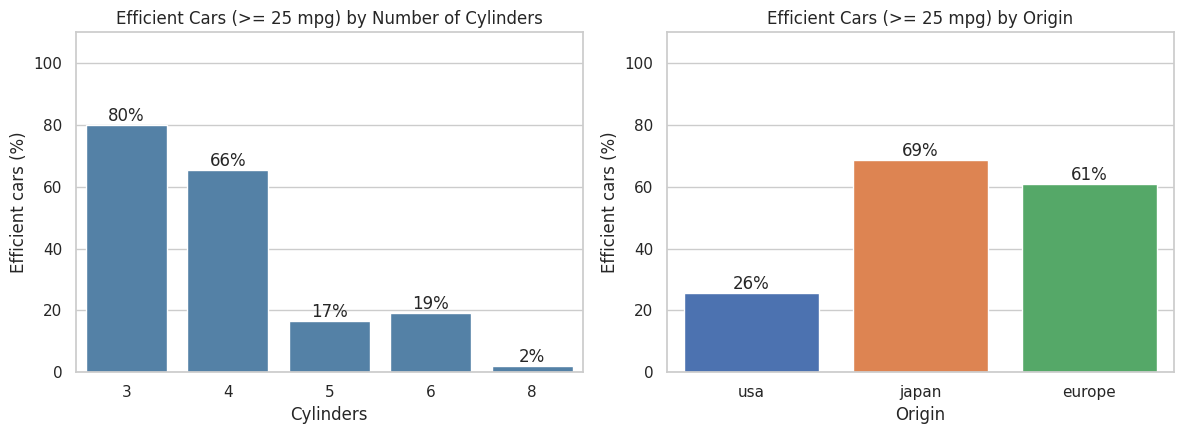

In [ ]:
# 5.1 Bar plots - share of efficient cars by cylinders and by origin
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.barplot(data=by_cyl.reset_index(), x='cylinders', y='Efficient_Pct', color='steelblue', ax=axes[0])
axes[0].bar_label(axes[0].containers[0], fmt='%.0f%%')
axes[0].set_title('Efficient Cars (>= 25 mpg) by Number of Cylinders')
axes[0].set_xlabel('Cylinders'); axes[0].set_ylabel('Efficient cars (%)'); axes[0].set_ylim(0, 110)

order = ['usa', 'japan', 'europe']
sns.barplot(data=by_origin.reset_index(), x='origin', y='Efficient_Pct', order=order, color='gray', ax=axes[1])
for bar, o in zip(axes[1].patches, order):          # give every origin its own colour
    bar.set_facecolor(ORIGIN_COLORS[o])
axes[1].bar_label(axes[1].containers[0], fmt='%.0f%%')
axes[1].set_title('Efficient Cars (>= 25 mpg) by Origin')
axes[1].set_xlabel('Origin'); axes[1].set_ylabel('Efficient cars (%)'); axes[1].set_ylim(0, 110)
plt.tight_layout()
plt.show()

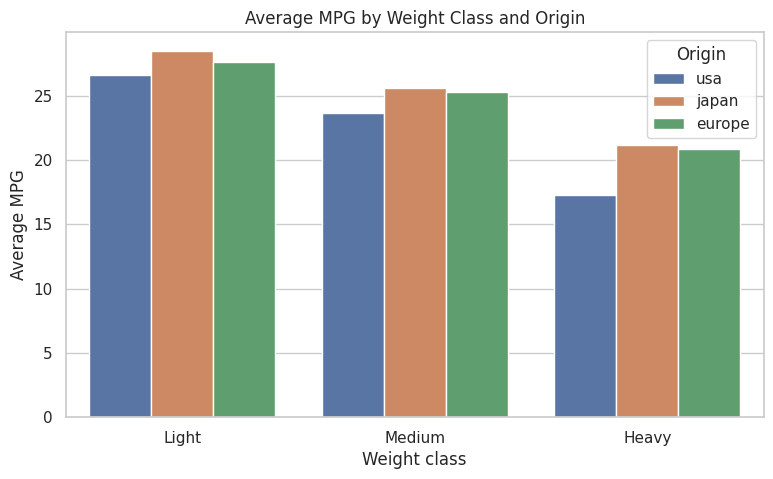

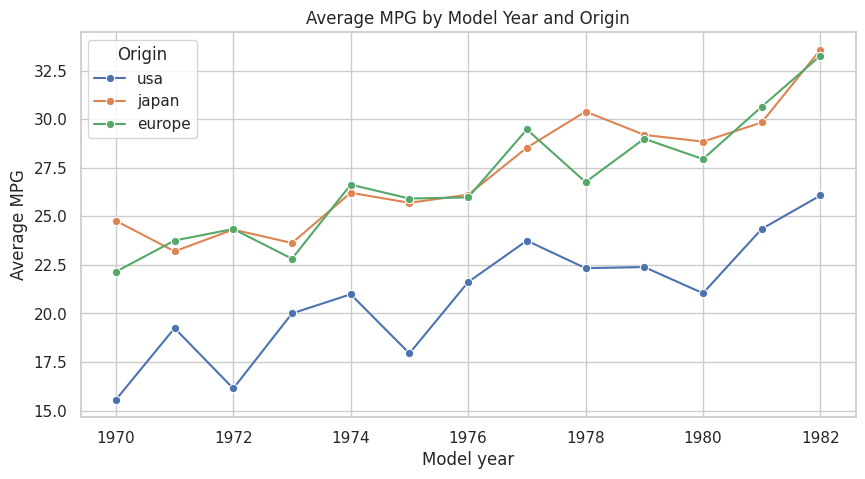

In [ ]:
# 5.2 Grouped bar plot - average MPG by weight class and origin
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=df, x='weight_class', y='mpg', hue='origin', hue_order=['usa', 'japan', 'europe'],
            palette=ORIGIN_COLORS, errorbar=None, ax=ax)
ax.set_title('Average MPG by Weight Class and Origin')
ax.set_xlabel('Weight class'); ax.set_ylabel('Average MPG')
ax.legend(title='Origin')
plt.show()

# 5.3 Line plot - average MPG per model year for each origin
fig, ax = plt.subplots(figsize=(10, 5))
sns.lineplot(data=df, x='year', y='mpg', hue='origin', hue_order=['usa', 'japan', 'europe'],
             palette=ORIGIN_COLORS, estimator='mean', errorbar=None, marker='o', ax=ax)
ax.set_title('Average MPG by Model Year and Origin')
ax.set_xlabel('Model year'); ax.set_ylabel('Average MPG')
ax.legend(title='Origin')
plt.show()

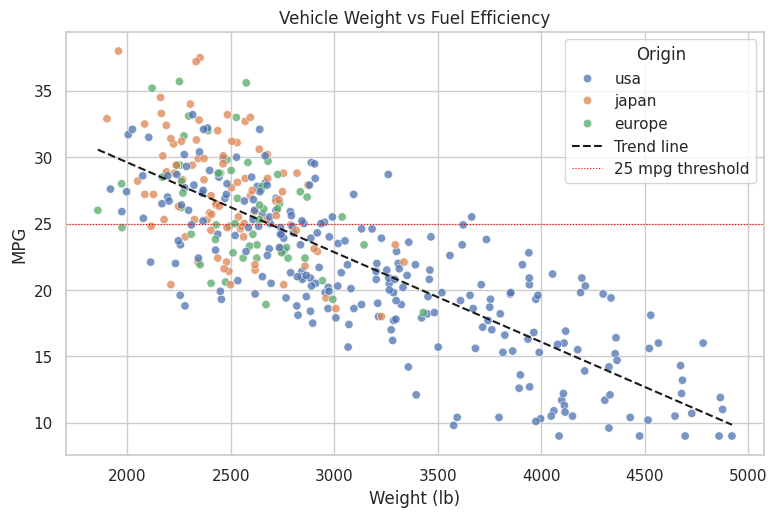

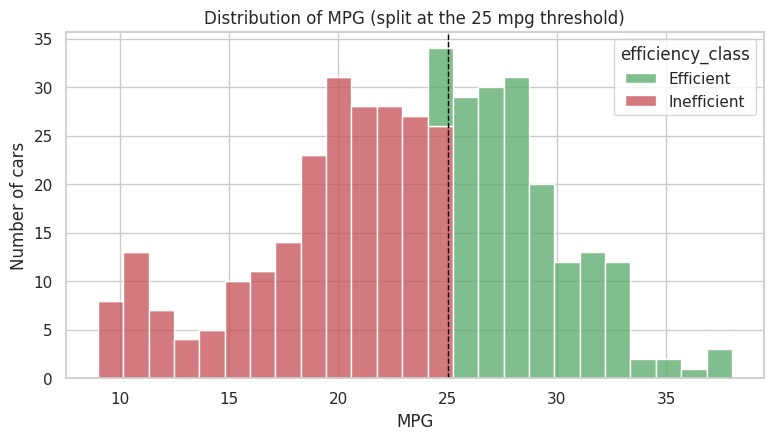

In [ ]:
# 5.4 Scatter plot - weight vs MPG with a trend line
fig, ax = plt.subplots(figsize=(9, 5.5))
sns.scatterplot(data=df, x='weight', y='mpg', hue='origin', hue_order=['usa', 'japan', 'europe'],
                palette=ORIGIN_COLORS, alpha=0.75, ax=ax)
m, c = np.polyfit(df['weight'], df['mpg'], 1)
xs = np.linspace(df['weight'].min(), df['weight'].max(), 100)
ax.plot(xs, m * xs + c, 'k--', linewidth=1.5, label='Trend line')
ax.axhline(25, color='red', linewidth=0.8, linestyle=':', label='25 mpg threshold')
ax.set_title('Vehicle Weight vs Fuel Efficiency')
ax.set_xlabel('Weight (lb)'); ax.set_ylabel('MPG')
ax.legend(title='Origin')
plt.show()

# 5.5 Histogram - distribution of MPG
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.histplot(data=df, x='mpg', hue='efficiency_class', bins=25, multiple='stack',
             palette={'Efficient': '#55A868', 'Inefficient': '#C44E52'}, ax=ax)
ax.axvline(25, color='black', linestyle='--', linewidth=1)
ax.set_title('Distribution of MPG (split at the 25 mpg threshold)')
ax.set_xlabel('MPG'); ax.set_ylabel('Number of cars')
plt.show()

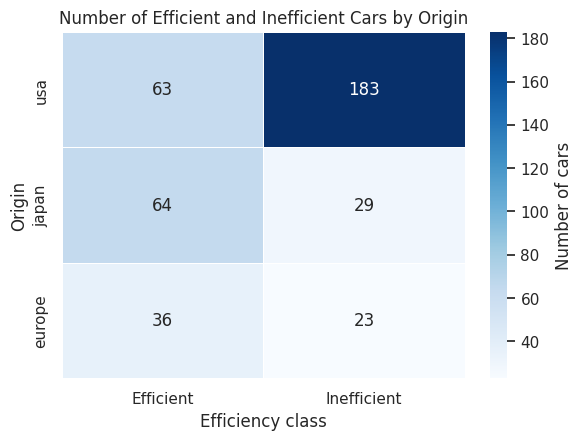

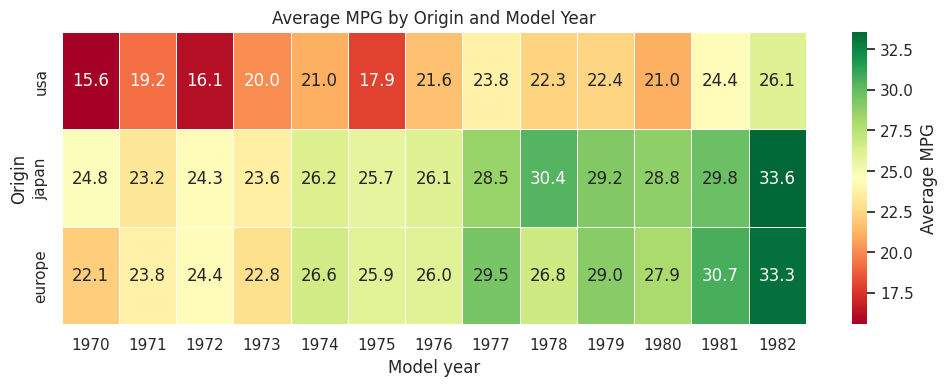

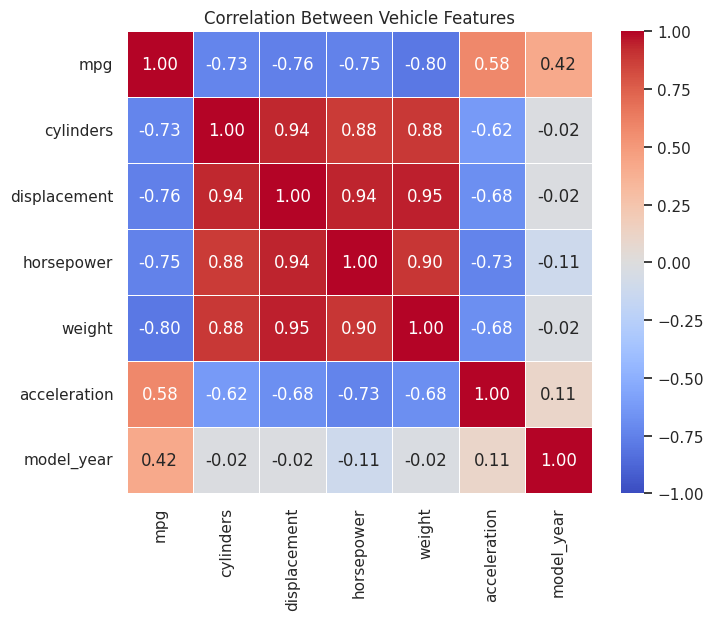

In [ ]:
# 5.6 Heatmap - number of efficient / inefficient cars per origin (analogue of survival counts by port)
# Recompute counts to avoid potential NameErrors if prior cells weren't run
counts = pd.crosstab(df['origin'], df['efficiency_class'])

fig, ax = plt.subplots(figsize=(6.5, 4.5))
sns.heatmap(counts.loc[['usa', 'japan', 'europe'], ['Efficient', 'Inefficient']], annot=True, fmt='.0f',
            cmap='Blues', linewidths=0.5, ax=ax, cbar_kws={'label': 'Number of cars'})
ax.set_title('Number of Efficient and Inefficient Cars by Origin')
ax.set_xlabel('Efficiency class'); ax.set_ylabel('Origin')
plt.show()

# 5.7 Heatmap - average MPG by origin and model year
pt_year = df.pivot_table(index='origin', columns='year', values='mpg', aggfunc='mean').loc[['usa', 'japan', 'europe']]
fig, ax = plt.subplots(figsize=(12, 3.8))
sns.heatmap(pt_year, annot=True, fmt='.1f', cmap='RdYlGn', linewidths=0.5, ax=ax,
            cbar_kws={'label': 'Average MPG'})
ax.set_title('Average MPG by Origin and Model Year')
ax.set_xlabel('Model year'); ax.set_ylabel('Origin')
plt.show()

# 5.8 Heatmap - correlation between numeric features
corr_cols = ['mpg', 'cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'model_year']
corr = df[corr_cols].corr()
fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5, ax=ax)
ax.set_title('Correlation Between Vehicle Features')
plt.show()

**Conclusion / Insight (Q5):** The bar plots show the efficient share collapsing as cylinders increase (80% -> 66% -> 17% -> 19% -> 2%) and a large origin gap (USA 26% vs Japan 69% and Europe 61%). In the grouped bar plot light cars beat medium cars and medium beat heavy ones in *every* origin, and the USA is lowest in each class, with the widest gap among heavy cars. The line plot shows MPG rising for all three origins from 1970 to 1982 (about +0.65 to +0.74 mpg per year), so the origin gap stays roughly constant over time rather than closing. The scatter plot confirms a clear downward linear trend (heavier = lower MPG) with American cars on the heavy, low-MPG side and Japanese/European cars on the light, high-MPG side; the histogram shows MPG is roughly bell-shaped around 23-24 mpg and the 25 mpg line separates 163 efficient from 235 inefficient cars.

In the heatmaps, the **dark "usa x Inefficient" cell (183 cars)** dominates the count heatmap; the origin x year heatmap becomes greener towards 1980-1982 (individual Japanese/European cells rest on only a few cars per year, so single values are noisy); and the correlation heatmap shows that MPG is negatively correlated with weight (-0.80), displacement (-0.76), horsepower (-0.75) and cylinders (-0.73) and positively with acceleration time (0.58) and model year (0.42). The size variables are themselves almost the same information (displacement-weight r = 0.95), while model year is nearly uncorrelated with them (|r| <= 0.11) - improvement over time is therefore a *separate* effect from downsizing.

## Auto-generated Key Facts (use as a cross-check for the conclusions above)

In [ ]:
# Recompute the aggregated dataframes locally to make this cell self-contained and avoid NameErrors
def summarize(g):
    return g.agg(Cars=('mpg', 'count'),
                 Avg_MPG=('mpg', 'mean'),
                 Avg_Weight=('weight', 'mean'),
                 Efficient_Pct=('is_efficient', lambda s: s.mean() * 100))

by_cyl    = summarize(df.groupby('cylinders'))
by_origin = summarize(df.groupby('origin'))
by_year   = summarize(df.groupby('year'))

brand_tbl = (df[df['brand'] != 'Unknown'].groupby('brand')
             .agg(Cars=('mpg', 'count'), Avg_MPG=('mpg', 'mean'), Avg_Weight=('weight', 'mean')))
brand_tbl = brand_tbl[brand_tbl['Cars'] >= 5]

eff_top   = by_origin['Efficient_Pct'].idxmax()
eff_low   = by_origin['Efficient_Pct'].idxmin()
brand_top = brand_tbl['Avg_MPG'].idxmax()
brand_low = brand_tbl['Avg_MPG'].idxmin()
pairs     = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
mpg_corr  = corr['mpg'].drop('mpg')

print(f'Cars analysed                 : {len(df)} ({df.year.min()} to {df.year.max()} models)')
print(f"Overall efficient cars        : {df['is_efficient'].mean() * 100:.1f}%   (average MPG {df.mpg.mean():.1f}, = {df.kmpl.mean():.1f} km/L)")
print(f'Most / least efficient origin : {eff_top} ({by_origin.loc[eff_top, "Efficient_Pct"]:.1f}%) / {eff_low} ({by_origin.loc[eff_low, "Efficient_Pct"]:.1f}%)')
print(f'Best / worst cylinder count   : {by_cyl["Avg_MPG"].idxmax()} cyl ({by_cyl["Avg_MPG"].max():.1f} mpg) / {by_cyl["Avg_MPG"].idxmin()} cyl ({by_cyl["Avg_MPG"].min():.1f} mpg)')
print(f'Best / worst brand (>=5 cars) : {brand_top} ({brand_tbl.loc[brand_top, "Avg_MPG"]:.1f} mpg) / {brand_low} ({brand_tbl.loc[brand_low, "Avg_MPG"]:.1f} mpg)')
print(f'Average MPG, first vs last yr : {by_year["Avg_MPG"].iloc[0]:.1f} ({by_year.index[0]}) -> {by_year["Avg_MPG"].iloc[-1]:.1f} ({by_year.index[-1]})')
print(f'Strongest negative correlation: {mpg_corr.idxmin()} ({mpg_corr.min():.2f});  strongest positive: {mpg_corr.idxmax()} ({mpg_corr.max():.2f})')
print(f'Most correlated feature pair  : {pairs.abs().idxmax()} ({pairs[pairs.abs().idxmax()]:.2f})')

Cars analysed                 : 398 (1970 to 1982 models)
Overall efficient cars        : 41.0%   (average MPG 23.2, = 9.9 km/L)
Most / least efficient origin : japan (68.8%) / usa (25.6%)
Best / worst cylinder count   : 3 cyl (31.0 mpg) / 8 cyl (16.2 mpg)
Best / worst brand (>=5 cars) : subaru (28.4 mpg) / amc (19.5 mpg)
Average MPG, first vs last yr : 19.2 (1970) -> 28.8 (1982)
Strongest negative correlation: weight (-0.80);  strongest positive: acceleration (0.58)
Most correlated feature pair  : ('displacement', 'weight') (0.95)


## Final Conclusion

The raw data had duplicates, text inside a numeric column, impossible values and missing entries; after cleaning (cylinder-group median imputation, `'Unknown'` for names, outliers kept because they are real V8 cars) the analysis covered 398 cars. **Fuel efficiency is mainly decided by size**: weight (r = -0.80), engine displacement and horsepower go hand in hand and each extra 1,000 lb costs about 6.8 mpg; only 2% of 8-cylinder cars reach 25 mpg compared with 66% of 4-cylinder cars. **Origin matters mostly through the car mix** - Japan (69%) and Europe (61%) sell small cars, the USA (26%) sells many heavy V8s - and even among cars of similar weight the Japanese and European models stay 1-3.5 mpg ahead. **Time helps**: average MPG improved from 19.2 to 28.8 between 1970 and 1982, independent of vehicle size. The trade-off for economy is performance: efficient cars have about 37 hp less and accelerate 1.7 s slower.

**Limitations:** the data covers only 398 cars of 1970-1982, some groups are tiny (3- and 5-cylinder cars, European and Japanese 6-cylinder cars), the values are simulated rather than measured, MPG is in US units (km/L is given for reference), and correlation does not prove causation because weight, displacement and horsepower are strongly inter-related. There is no information on fuel type, transmission or aerodynamics.

**Future Work:** fit a multiple linear regression (or decision tree) to predict MPG from weight, horsepower and year; classify cars as Efficient/Inefficient; include modern vehicles with hybrid/electric drive-trains; convert fuel use to CO2 emissions per kilometre.